**Libraries Import**


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')

**Dataset** **Upload**

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving songs_normalize.csv to songs_normalize (1).csv


**Upload the Dataset and Print First 5 Rows**


In [ ]:
df = pd.read_csv("songs_normalize.csv")
df.head()



,artist,song,duration_ms,explicit,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,genre
0,Britney Spears,Oops!...I Did It Again,211160,False,2000,77,0.751,0.834,1,-5.444,0,0.0437,0.3000,0.000018,0.3550,0.894,95.053,pop
1,blink-182,All The Small Things,167066,False,1999,79,0.434,0.897,0,-4.918,1,0.0488,0.0103,0.000000,0.6120,0.684,148.726,"rock, pop"
2,Faith Hill,Breathe,250546,False,1999,66,0.529,0.496,7,-9.007,1,0.0290,0.1730,0.000000,0.2510,0.278,136.859,"pop, country"
3,Bon Jovi,It's My Life,224493,False,2000,78,0.551,0.913,0,-4.063,0,0.0466,0.0263,0.000013,0.3470,0.544,119.992,"rock, metal"
4,*NSYNC,Bye Bye Bye,200560,False,2000,65,0.614,0.928,8,-4.806,0,0.0516,0.0408,0.001040,0.0845,0.879,172.656,pop


**Dataset Size**

In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 2000
Columns: 18


**Columns Names**


In [ ]:
print(df.columns.tolist())

['artist', 'song', 'duration_ms', 'explicit', 'year', 'popularity', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'genre']


**Dataset Information**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   artist            2000 non-null   object 
 1   song              2000 non-null   object 
 2   duration_ms       2000 non-null   int64  
 3   explicit          2000 non-null   bool   
 4   year              2000 non-null   int64  
 5   popularity        2000 non-null   int64  
 6   danceability      2000 non-null   float64
 7   energy            2000 non-null   float64
 8   key               2000 non-null   int64  
 9   loudness          2000 non-null   float64
 10  mode              2000 non-null   int64  
 11  speechiness       2000 non-null   float64
 12  acousticness      2000 non-null   float64
 13  instrumentalness  2000 non-null   float64
 14  liveness          2000 non-null   float64
 15  valence           2000 non-null   float64
 16  tempo             2000 non-null   float64


**Statistical Summary**

In [ ]:
df.describe()

,duration_ms,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo
count,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,228748.124500,2009.49400,59.872500,0.667438,0.720366,5.378000,-5.512434,0.553500,0.103568,0.128955,0.015226,0.181216,0.551690,120.122558
std,39136.569008,5.85996,21.335577,0.140416,0.152745,3.615059,1.933482,0.497254,0.096159,0.173346,0.087771,0.140669,0.220864,26.967112
min,113000.000000,1998.00000,0.000000,0.129000,0.054900,0.000000,-20.514000,0.000000,0.023200,0.000019,0.000000,0.021500,0.038100,60.019000
25%,203580.000000,2004.00000,56.000000,0.581000,0.622000,2.000000,-6.490250,0.000000,0.039600,0.014000,0.000000,0.088100,0.386750,98.985750
50%,223279.500000,2010.00000,65.500000,0.676000,0.736000,6.000000,-5.285000,1.000000,0.059850,0.055700,0.000000,0.124000,0.557500,120.021500
75%,248133.000000,2015.00000,73.000000,0.764000,0.839000,8.000000,-4.167750,1.000000,0.129000,0.176250,0.000068,0.241000,0.730000,134.265500
max,484146.000000,2020.00000,89.000000,0.975000,0.999000,11.000000,-0.276000,1.000000,0.576000,0.976000,0.985000,0.853000,0.973000,210.851000


**Missing Values Check with Percentage**

In [ ]:
df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage.sort_values(ascending=False))

artist              0.0
song                0.0
duration_ms         0.0
explicit            0.0
year                0.0
popularity          0.0
danceability        0.0
energy              0.0
key                 0.0
loudness            0.0
mode                0.0
speechiness         0.0
acousticness        0.0
instrumentalness    0.0
liveness            0.0
valence             0.0
tempo               0.0
genre               0.0
dtype: float64


**Duplicate Check**

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 59


**Omit Duplicate Values**

In [ ]:
df = df.drop_duplicates()
print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (1941, 18)


**Column Names Check**

In [ ]:
print(df.columns.tolist())

['artist', 'song', 'duration_ms', 'explicit', 'year', 'popularity', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'genre']


**Numerical Features Select and Checking**

In [ ]:
features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

df[features].head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.751,0.834,-5.444,0.0437,0.3000,0.000018,0.3550,0.894,95.053
1,0.434,0.897,-4.918,0.0488,0.0103,0.000000,0.6120,0.684,148.726
2,0.529,0.496,-9.007,0.0290,0.1730,0.000000,0.2510,0.278,136.859
3,0.551,0.913,-4.063,0.0466,0.0263,0.000013,0.3470,0.544,119.992
4,0.614,0.928,-4.806,0.0516,0.0408,0.001040,0.0845,0.879,172.656


Target Variable

Score:
0-39, 40-69, 70-100

Category:
Not Popular, Moderately Popular, Popular

**Create Popularity Category**

In [ ]:
def popularity_category(score):
    if score >= 70:
        return "Popular"
    elif score >= 40:
        return "Moderately Popular"
    else:
        return "Not Popular"

df['popularity_category'] = df['popularity'].apply(popularity_category)

df[['popularity', 'popularity_category']].head(20)

,popularity,popularity_category
0,77,Popular
1,79,Popular
2,66,Moderately Popular
3,78,Popular
4,65,Moderately Popular
5,69,Moderately Popular
6,86,Popular
7,68,Moderately Popular
8,75,Popular
9,77,Popular


**Category Distribution with Percentage**

In [ ]:
print(df['popularity_category'].value_counts())
print(df['popularity_category'].value_counts(normalize=True)*100)

popularity_category
Moderately Popular    1026
Popular                699
Not Popular            216
Name: count, dtype: int64
popularity_category
Moderately Popular    52.859351
Popular               36.012365
Not Popular           11.128284
Name: proportion, dtype: float64


**EDA: Popularity Distribution**

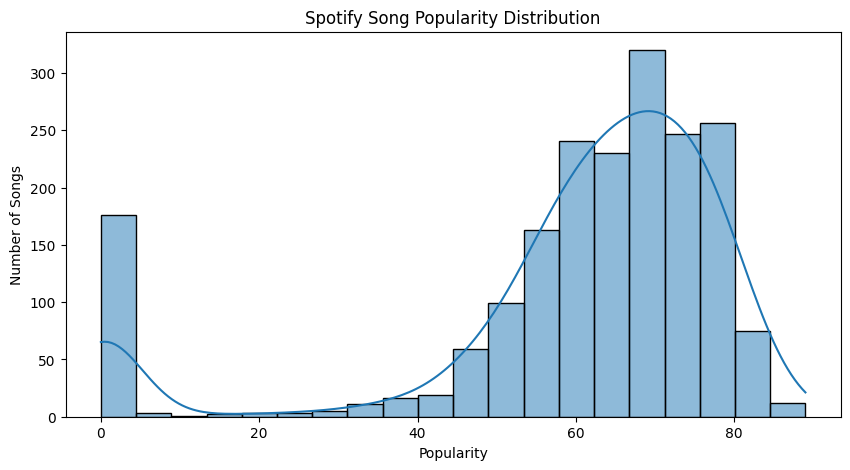

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(
    df['popularity'],
    bins=20,
    kde=True
)

plt.title("Spotify Song Popularity Distribution")
plt.xlabel("Popularity")
plt.ylabel("Number of Songs")

plt.show()

**Popularity Classes Visualization**

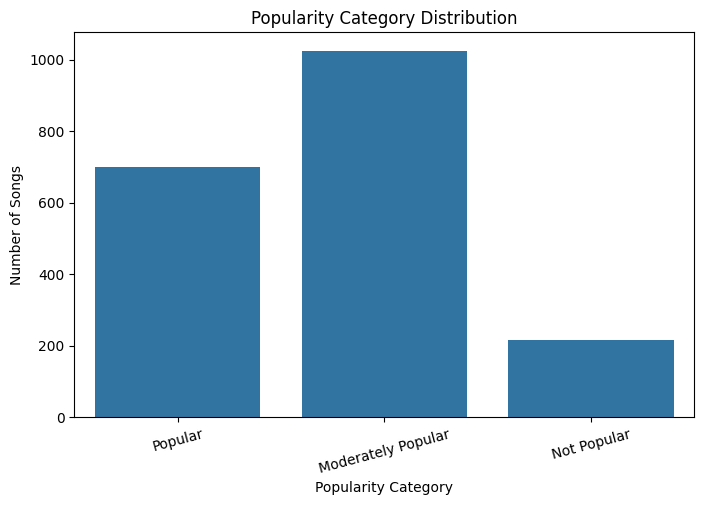

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='popularity_category'
)

plt.title("Popularity Category Distribution")
plt.xlabel("Popularity Category")
plt.ylabel("Number of Songs")

plt.xticks(rotation=15)

plt.show()

**Feature Distribution**

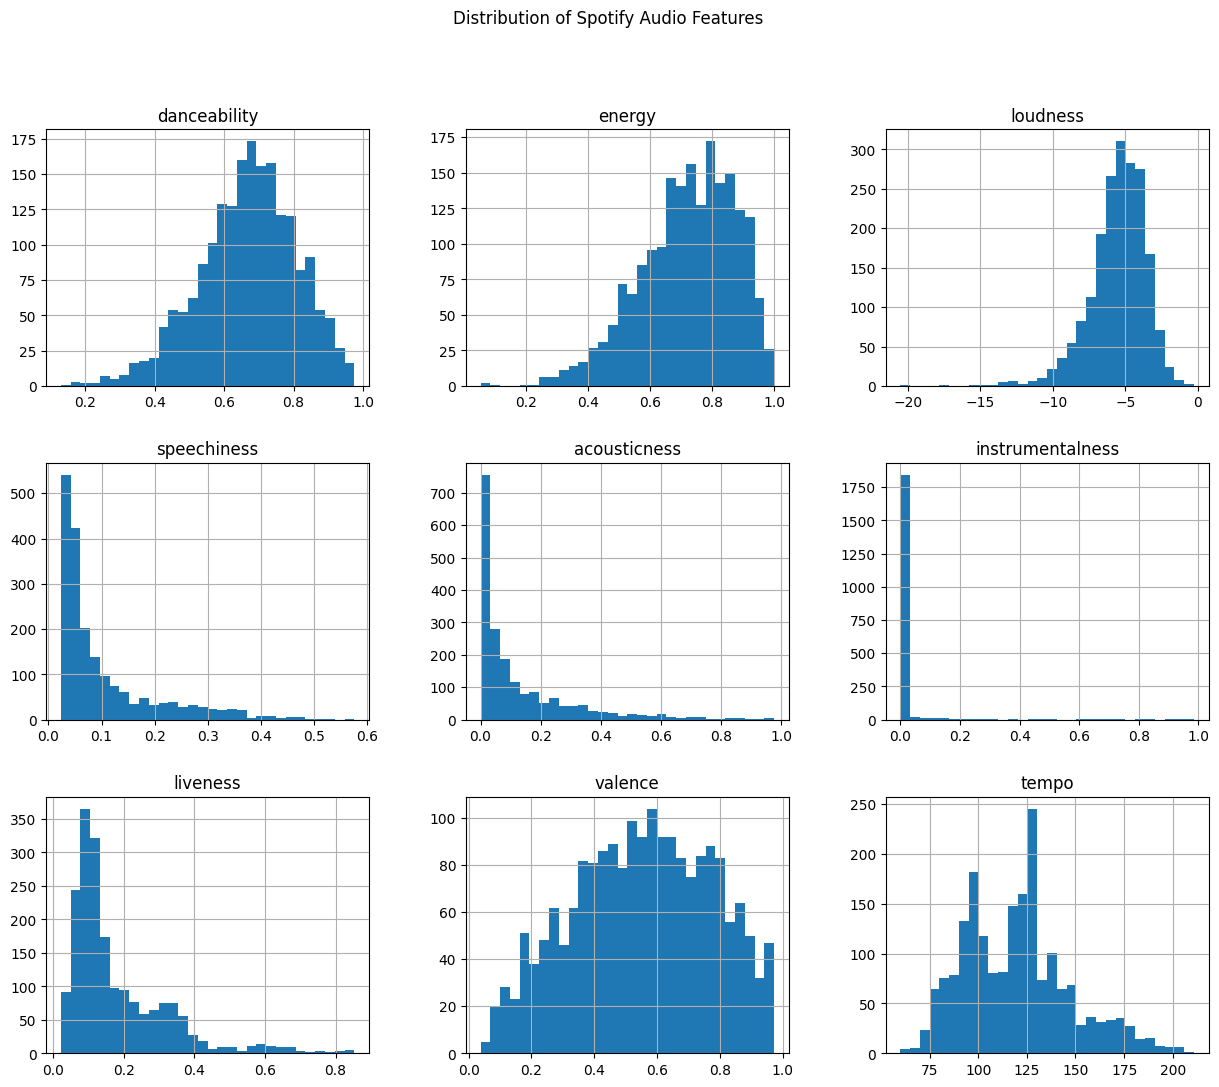

In [ ]:
df[features].hist(
    figsize=(15,12),
    bins=30
)

plt.suptitle("Distribution of Spotify Audio Features")

plt.show()

**Correlation Heatmap**

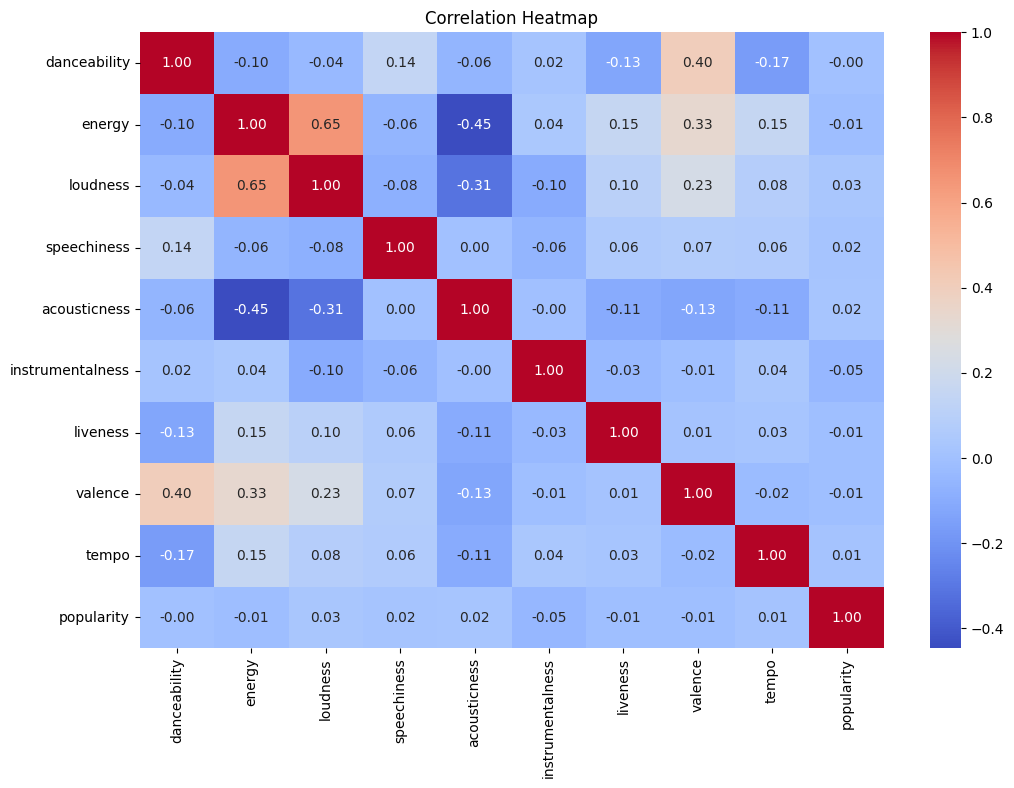

In [ ]:
plt.figure(figsize=(12,8))

correlation = df[features + ['popularity']].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

**Scatter Plots
1.Danceability vs Popularity**

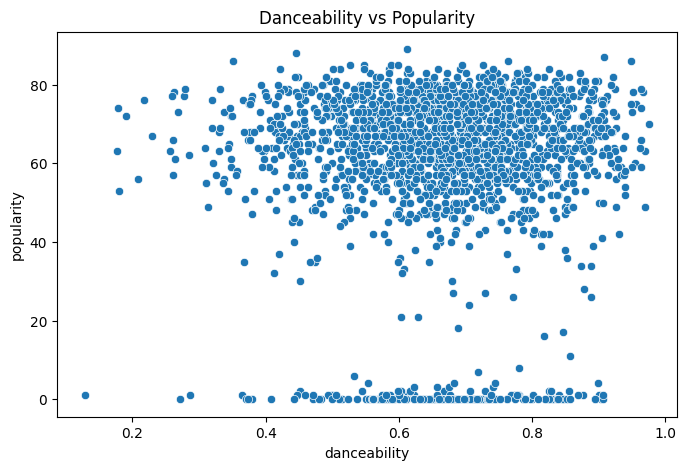

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='danceability',
    y='popularity'
)

plt.title("Danceability vs Popularity")
plt.show()

**2.Energy vs Popularity**

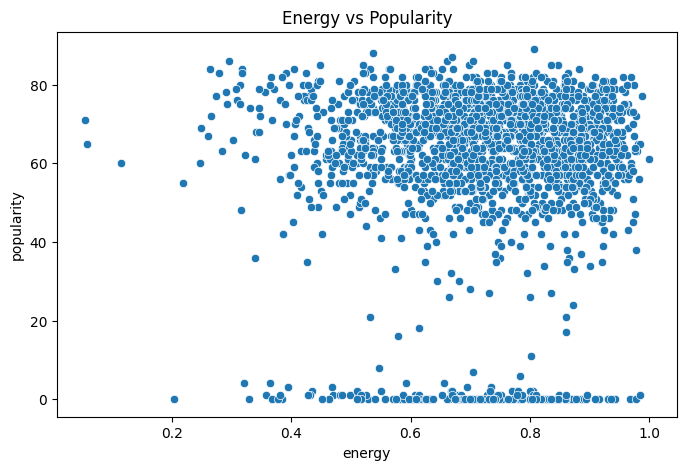

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='energy',
    y='popularity'
)

plt.title("Energy vs Popularity")
plt.show()

**3.Valence vs Popularity**

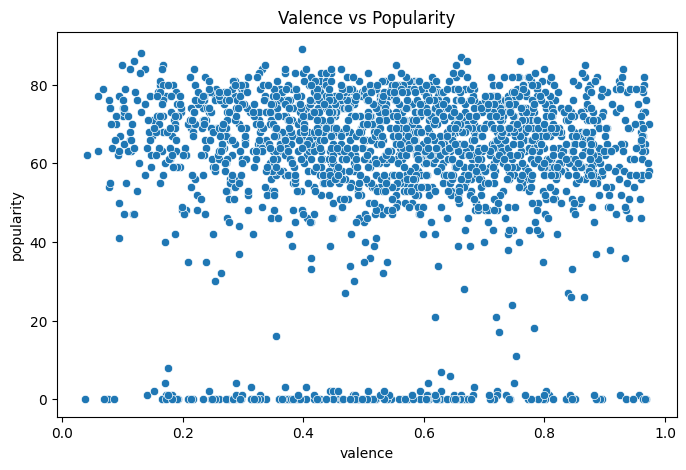

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='valence',
    y='popularity'
)

plt.title("Valence vs Popularity")
plt.show()

**Preparation of X and Y and Checking**

In [ ]:
X = df[features]

y = df['popularity_category']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1941, 9)
y shape: (1941,)


**Train-Test Split and Checking**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1552, 9)
Testing data: (389, 9)


**Feature Scaling Using Standard Scaler**

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Scaled training data: (1552, 9)
Scaled testing data: (389, 9)


**Logistic Regression and Prediction**

In [ ]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)
y_pred_logistic = logistic_model.predict(X_test_scaled)

print("===== Logistic Regression =====")
print("Model trained successfully!")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)
print("Predictions generated:", len(y_pred_logistic))
print("First 10 predictions:")
print(y_pred_logistic[:10])

===== Logistic Regression =====
Model trained successfully!
Training data shape: (1552, 9)
Testing data shape: (389, 9)
Predictions generated: 389
First 10 predictions:
['Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular' 'Popular' 'Moderately Popular'
 'Popular' 'Popular' 'Moderately Popular']


**Decision Tree and Prediction**

In [ ]:
from sklearn.tree import DecisionTreeClassifier
decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)
decision_tree.fit(X_train, y_train)
y_pred_tree = decision_tree.predict(X_test)
print("===== Decision Tree =====")
print("Model trained successfully!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Predictions generated:", len(y_pred_tree))
print("First 10 predictions:")
print(y_pred_tree[:10])

===== Decision Tree =====
Model trained successfully!
Training data shape: (1552, 9)
Testing data shape: (389, 9)
Predictions generated: 389
First 10 predictions:
['Moderately Popular' 'Popular' 'Popular' 'Moderately Popular' 'Popular'
 'Popular' 'Popular' 'Popular' 'Popular' 'Moderately Popular']


**Random Forest**

In [ ]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)

print("===== Random Forest =====")
print("Model trained successfully!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Predictions generated:", len(y_pred_rf))
print("First 10 predictions:")
print(y_pred_rf[:10])

===== Random Forest =====
Model trained successfully!
Training data shape: (1552, 9)
Testing data shape: (389, 9)
Predictions generated: 389
First 10 predictions:
['Moderately Popular' 'Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Popular' 'Moderately Popular']


**Model Evaluation Function**

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

def evaluate_model(name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    print("=" * 50)
    print(name)
    print("=" * 50)

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    return accuracy, precision, recall, f1

**Evaluate Logistic Regression**

In [ ]:
logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_logistic
)

Logistic Regression
Accuracy : 0.5141
Precision: 0.4285
Recall   : 0.5141
F1 Score : 0.4368

Classification Report:
                    precision    recall  f1-score   support

Moderately Popular       0.54      0.85      0.66       206
       Not Popular       0.00      0.00      0.00        43
           Popular       0.40      0.18      0.25       140

          accuracy                           0.51       389
         macro avg       0.31      0.34      0.30       389
      weighted avg       0.43      0.51      0.44       389



**Evaluate Decision Tree**

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

tree_results = evaluate_model(
    "Decision Tree",
    y_test,
    y_pred_tree
)

Decision Tree
Accuracy : 0.4602
Precision: 0.4348
Recall   : 0.4602
F1 Score : 0.446

Classification Report:
                    precision    recall  f1-score   support

Moderately Popular       0.54      0.56      0.55       206
       Not Popular       0.06      0.02      0.03        43
           Popular       0.39      0.44      0.42       140

          accuracy                           0.46       389
         macro avg       0.33      0.34      0.33       389
      weighted avg       0.43      0.46      0.45       389



**Evaluate Random Forest**

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    y_pred_rf
)

Random Forest
Accuracy : 0.4961
Precision: 0.4168
Recall   : 0.4961
F1 Score : 0.4421

Classification Report:
                    precision    recall  f1-score   support

Moderately Popular       0.54      0.77      0.63       206
       Not Popular       0.00      0.00      0.00        43
           Popular       0.36      0.25      0.30       140

          accuracy                           0.50       389
         macro avg       0.30      0.34      0.31       389
      weighted avg       0.42      0.50      0.44       389



**Model Comparison**

In [ ]:
import pandas as pd

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],

    'Accuracy': [
        logistic_results[0],
        tree_results[0],
        rf_results[0]
    ],

    'Precision': [
        logistic_results[1],
        tree_results[1],
        rf_results[1]
    ],

    'Recall': [
        logistic_results[2],
        tree_results[2],
        rf_results[2]
    ],

    'F1 Score': [
        logistic_results[3],
        tree_results[3],
        rf_results[3]
    ]
})

print("===== Model Performance Comparison =====")
display(results)

===== Model Performance Comparison =====


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.514139,0.428525,0.514139,0.436827
1,Decision Tree,0.460154,0.434781,0.460154,0.445961
2,Random Forest,0.496144,0.416779,0.496144,0.442104


**Model Comparison Graph**

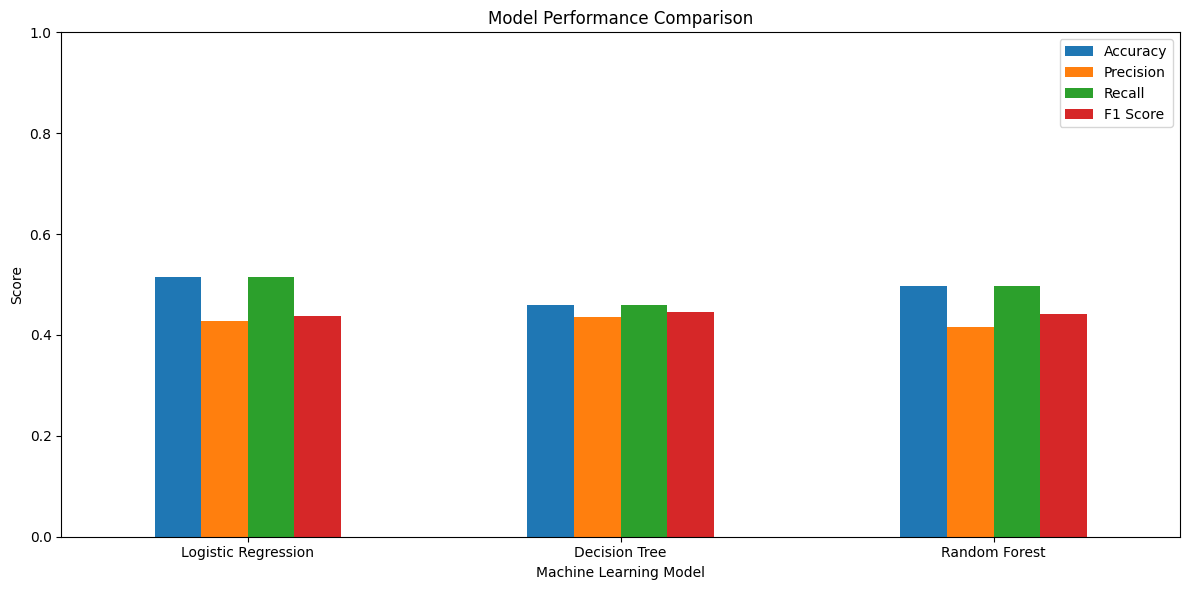

In [ ]:
import matplotlib.pyplot as plt

results.set_index('Model').plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

**Confusion Matrix**

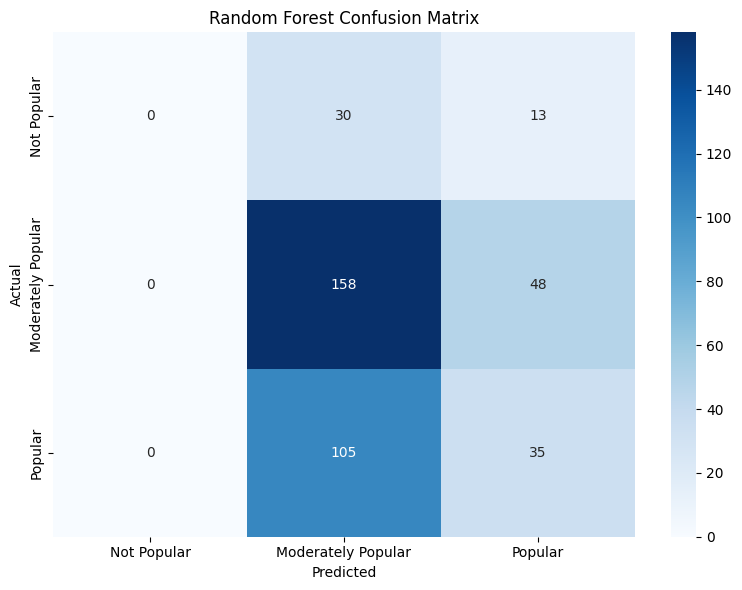

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=[
        'Not Popular',
        'Moderately Popular',
        'Popular'
    ]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[
        'Not Popular',
        'Moderately Popular',
        'Popular'
    ],
    yticklabels=[
        'Not Popular',
        'Moderately Popular',
        'Popular'
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.tight_layout()
plt.show()

**Feature Independence**
**1. Calculate Feature Importance**

In [ ]:
import pandas as pd

importance = pd.DataFrame({
    'Feature': features,
    'Importance': random_forest.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("===== Feature Importance =====")
display(importance)

===== Feature Importance =====


,Feature,Importance
4,acousticness,0.121078
6,liveness,0.120917
1,energy,0.120749
7,valence,0.119796
3,speechiness,0.115688
2,loudness,0.115326
0,danceability,0.113343
8,tempo,0.111934
5,instrumentalness,0.061169


**2. Feature Importance Graph**

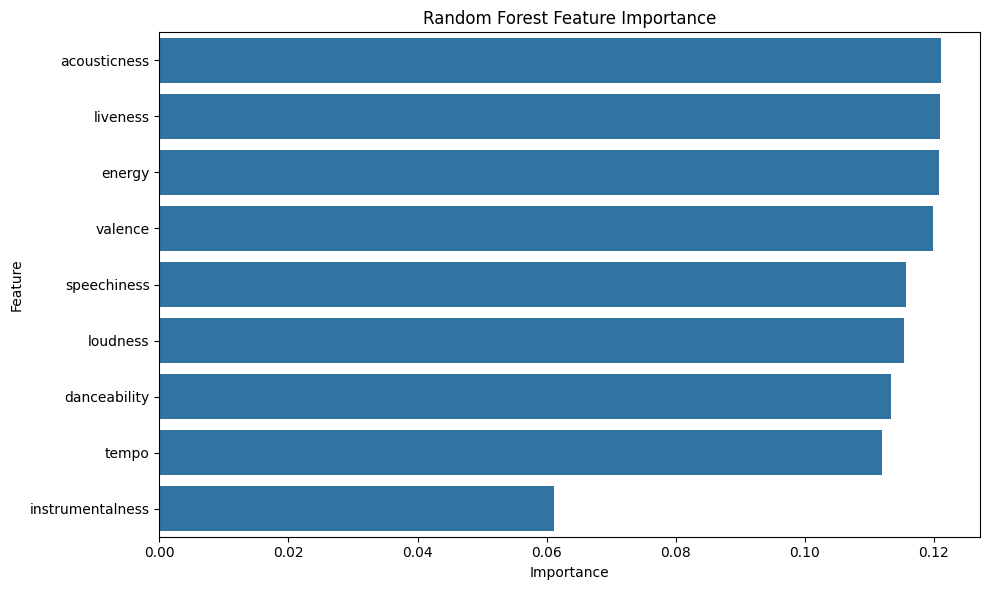

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

**New Song Prediction**
**1.Import Pandas**

In [ ]:
import pandas as pd

**2.Create New Song**

In [ ]:
new_song = pd.DataFrame({
    'danceability': [0.80],
    'energy': [0.75],
    'loudness': [-5.0],
    'speechiness': [0.05],
    'acousticness': [0.10],
    'instrumentalness': [0.01],
    'liveness': [0.10],
    'valence': [0.80],
    'tempo': [120]
})

print("===== New Song Features =====")
display(new_song)

===== New Song Features =====


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.8,0.75,-5.0,0.05,0.1,0.01,0.1,0.8,120


**3. Predict Popularity**

In [ ]:
prediction = random_forest.predict(new_song)

print("===== Prediction Result =====")
print("Predicted Popularity Category:", prediction[0])

===== Prediction Result =====
Predicted Popularity Category: Moderately Popular


**4. Prediction Probability**

In [ ]:
probability = random_forest.predict_proba(new_song)

print("===== Prediction Probabilities =====")

for category, prob in zip(
    random_forest.classes_,
    probability[0]
):
    print(f"{category}: {prob * 100:.2f}%")

===== Prediction Probabilities =====
Moderately Popular: 69.00%
Not Popular: 6.50%
Popular: 24.50%
